In [3]:
import pandas as pd
import numpy as np

In [4]:
df= pd.read_csv("/content/Telcom-Customer-Churn.csv")

In [5]:
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [6]:
df.info

<bound method DataFrame.info of       customerID  gender  SeniorCitizen Partner Dependents  tenure  \
0     7590-VHVEG  Female              0     Yes         No       1   
1     5575-GNVDE    Male              0      No         No      34   
2     3668-QPYBK    Male              0      No         No       2   
3     7795-CFOCW    Male              0      No         No      45   
4     9237-HQITU  Female              0      No         No       2   
...          ...     ...            ...     ...        ...     ...   
7038  6840-RESVB    Male              0     Yes        Yes      24   
7039  2234-XADUH  Female              0     Yes        Yes      72   
7040  4801-JZAZL  Female              0     Yes        Yes      11   
7041  8361-LTMKD    Male              1     Yes         No       4   
7042  3186-AJIEK    Male              0      No         No      66   

     PhoneService     MultipleLines InternetService OnlineSecurity  ...  \
0              No  No phone service             DSL             No  ...   
1             Yes                No             DSL            Yes  ...   
2             Yes                No             DSL            Yes  ...   
3              No  No phone service             DSL            Yes  ...   
4             Yes                No     Fiber optic             No  ...   
...           ...               ...             ...            ...  ...   
7038          Yes               Yes             DSL            Yes  ...   
7039          Yes               Yes     Fiber optic             No  ...   
7040           No  No phone service             DSL            Yes  ...   
7041          Yes               Yes     Fiber optic             No  ...   
7042          Yes                No     Fiber optic            Yes  ...   

     DeviceProtection TechSupport StreamingTV StreamingMovies        Contract  \
0                  No          No          No              No  Month-to-month   
1                 Yes          No          No              No        One year   
2                  No          No          No              No  Month-to-month   
3                 Yes         Yes          No              No        One year   
4                  No          No          No              No  Month-to-month   
...               ...         ...         ...             ...             ...   
7038              Yes         Yes         Yes             Yes        One year   
7039              Yes          No         Yes             Yes        One year   
7040               No          No          No              No  Month-to-month   
7041               No          No          No              No  Month-to-month   
7042              Yes         Yes         Yes             Yes        Two year   

     PaperlessBilling              PaymentMethod MonthlyCharges  TotalCharges  \
0                 Yes           Electronic check          29.85         29.85   
1                  No               Mailed check          56.95        1889.5   
2                 Yes               Mailed check          53.85        108.15   
3                  No  Bank transfer (automatic)          42.30       1840.75   
4                 Yes           Electronic check          70.70        151.65   
...               ...                        ...            ...           ...   
7038              Yes               Mailed check          84.80        1990.5   
7039              Yes    Credit card (automatic)         103.20        7362.9   
7040              Yes           Electronic check          29.60        346.45   
7041              Yes               Mailed check          74.40         306.6   
7042              Yes  Bank transfer (automatic)         105.65        6844.5   

     Churn  
0       No  
1       No  
2      Yes  
3       No  
4      Yes  
...    ...  
7038    No  
7039    No  
7040    No  
7041   Yes  
7042    No  

[7043 rows x 21 columns]>

In [7]:
df.columns

Index(['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents',
       'tenure', 'PhoneService', 'MultipleLines', 'InternetService',
       'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport',
       'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling',
       'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn'],
      dtype='object')

In [8]:
df["Churn"].unique()

array(['No', 'Yes'], dtype=object)

In [9]:
df["Churn"].value_counts()

,count
Churn,
No,5174
Yes,1869


Lab_8

In [10]:
X = df.drop("Churn", axis=1)
y = df["Churn"]

In [11]:
from sklearn.preprocessing import LabelEncoder
le = LabelEncoder()
for column in X.select_dtypes(include=["object"]).columns:
    X[column] = le.fit_transform(X[column])
y = le.fit_transform(y)

In [12]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split( X,
 y, test_size=0.2, random_state=42 )

In [13]:
from sklearn.linear_model import LogisticRegression

In [14]:
model = LogisticRegression(max_iter=1000)

In [15]:
model.fit(X_train, y_train)

/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


LogisticRegression(max_iter=1000)

In [16]:
y_pred = model.predict(X_test)

In [17]:
y_pred[:10]

array([1, 0, 0, 1, 0, 0, 0, 0, 0, 0])

In [18]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    roc_auc_score,
    classification_report
)

In [19]:
accuracy = accuracy_score(y_test, y_pred)

print("Accuracy Score:", accuracy)

Accuracy Score: 0.8204400283889283


In [20]:
precision = precision_score(y_test, y_pred)

print("Precision Score:", precision)

Precision Score: 0.6935483870967742


In [21]:
recall = recall_score(y_test, y_pred)

print("Recall Score:", recall)

Recall Score: 0.5764075067024129


In [22]:
f1 = f1_score(y_test, y_pred)

print("F1 Score:", f1)

F1 Score: 0.6295754026354319


In [23]:
cm = confusion_matrix(y_test, y_pred)

print(cm)

[[941  95]
 [158 215]]


In [24]:
y_prob = model.predict_proba(X_test)[:, 1]

roc_auc = roc_auc_score(y_test, y_prob)

print("ROC-AUC Score:", roc_auc)

ROC-AUC Score: 0.8602792758288738


In [25]:
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.86      0.91      0.88      1036
           1       0.69      0.58      0.63       373

    accuracy                           0.82      1409
   macro avg       0.77      0.74      0.76      1409
weighted avg       0.81      0.82      0.81      1409



ML_9

In [26]:
train_accuracy = model.score(X_train, y_train)
test_accuracy = model.score(X_test, y_test)
print("Training Accurancy:", train_accuracy)
print("Testing Accuracy:", test_accuracy)

Training Accurancy: 0.8001419950301739
Testing Accuracy: 0.8204400283889283


In [27]:
from sklearn.tree import DecisionTreeClassifier

In [28]:
dt1 = DecisionTreeClassifier(random_state=42)

In [29]:
dt1.fit(X_train, y_train)

y_pred_dt = dt1.predict(X_test)

In [30]:
print("Accuracy:", accuracy_score(y_test, y_pred_dt))
print("Precision:", precision_score(y_test, y_pred_dt))
print("Recall:", recall_score(y_test, y_pred_dt))
print("F1-Score:", f1_score(y_test, y_pred_dt))
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred_dt))

y_prob_dt = dt1.predict_proba(X_test)[:, 1]
print("ROC-AUC Score:", roc_auc_score(y_test, y_prob_dt))

Accuracy: 0.7189496096522356
Precision: 0.46981627296587924
Recall: 0.47989276139410186
F1-Score: 0.47480106100795755
Confusion Matrix:
 [[834 202]
 [194 179]]
ROC-AUC Score: 0.6424560332067035


In [31]:
from sklearn.metrics import classification_report

# Generate predictions
y_pred_dt = dt1.predict(X_test)

# Display Classification Report
print("Classification Report:\n")
print(classification_report(y_test, y_pred_dt))

Classification Report:

              precision    recall  f1-score   support

           0       0.81      0.81      0.81      1036
           1       0.47      0.48      0.47       373

    accuracy                           0.72      1409
   macro avg       0.64      0.64      0.64      1409
weighted avg       0.72      0.72      0.72      1409



In [32]:
dt2 = DecisionTreeClassifier(
    max_depth=2
)

dt2.fit(X_train, y_train)

DecisionTreeClassifier(max_depth=2)

In [33]:
y_pred_dt2 = dt2.predict(X_test)

In [34]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred_dt2))

              precision    recall  f1-score   support

           0       0.88      0.75      0.81      1036
           1       0.51      0.73      0.60       373

    accuracy                           0.74      1409
   macro avg       0.69      0.74      0.70      1409
weighted avg       0.78      0.74      0.75      1409



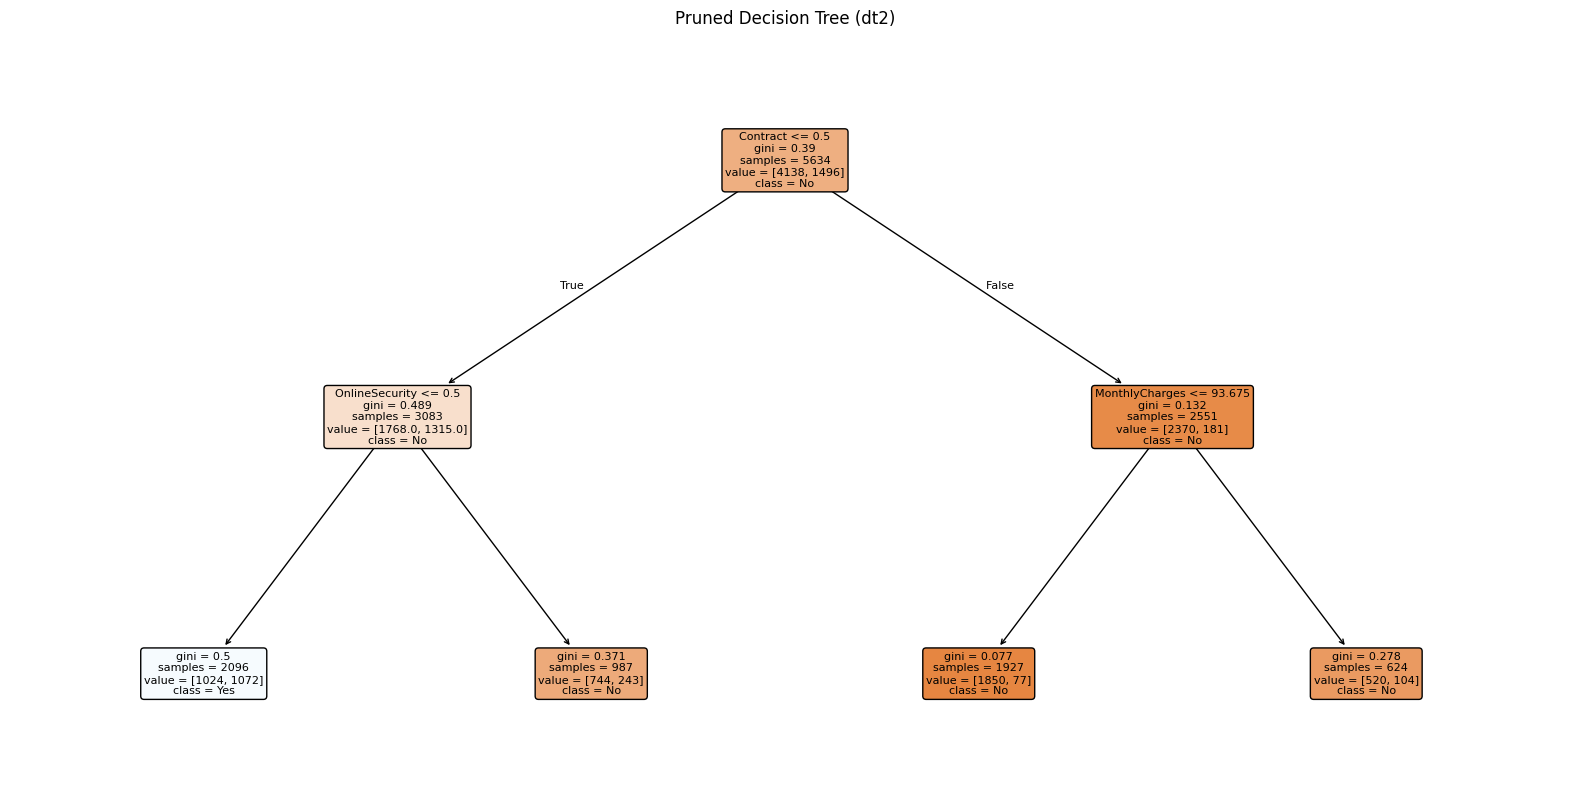

In [35]:
import matplotlib.pyplot as plt
from sklearn.tree import plot_tree

plt.figure(figsize=(20,10))

plot_tree(
    dt2,
    feature_names=X_train.columns,
    class_names=["No", "Yes"],
    filled=True,
    rounded=True,
    fontsize=8
)

plt.title("Pruned Decision Tree (dt2)")
plt.show()

ML_10


In [36]:
from sklearn.svm import  LinearSVC

In [37]:
svc = LinearSVC(random_state=1,C=0.09)

In [38]:
svc.fit(X_train, y_train)

LinearSVC(C=0.09, random_state=1)

In [39]:
y_pred_svc = svc.predict(X_test)

In [40]:
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
	f1_score, confusion_matrix, roc_auc_score, classification_report)
# Accuracy
print("Accuracy:", accuracy_score(y_test, y_pred_svc))
# Precision
print("Precision:", precision_score(y_test, y_pred_svc))
# Recall
print("Recall:", recall_score(y_test, y_pred_svc))
# F1-Score
print("F1-Score:", f1_score(y_test, y_pred_svc))
# Confusion Matrix
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred_svc))
# ROC-AUC Score
print("ROC-AUC Score:", roc_auc_score(y_test, y_pred_svc))
# Classification Report
print("Classification Report:\n")
print(classification_report(y_test, y_pred_svc))

Accuracy: 0.8126330731014905
Precision: 0.6775244299674267
Recall: 0.5576407506702413
F1-Score: 0.611764705882353
Confusion Matrix:
 [[937  99]
 [165 208]]
ROC-AUC Score: 0.7310404525551979
Classification Report:

              precision    recall  f1-score   support

           0       0.85      0.90      0.88      1036
           1       0.68      0.56      0.61       373

    accuracy                           0.81      1409
   macro avg       0.76      0.73      0.74      1409
weighted avg       0.80      0.81      0.81      1409



In [41]:
from sklearn.svm import SVC

poly_svc = SVC(kernel="poly", probability=True, random_state=42)

In [42]:
poly_svc.fit(X_train, y_train)
y_pred_poly_svc = poly_svc.predict(X_test)

In [43]:
print("Accuracy:", accuracy_score(y_test, y_pred_poly_svc))
print("Precision:", precision_score(y_test, y_pred_poly_svc))
print("Recall:", recall_score(y_test, y_pred_poly_svc))
print("F1-Score:", f1_score(y_test, y_pred_poly_svc))
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred_poly_svc))
print("ROC-AUC Score:", roc_auc_score(y_test, poly_svc.predict_proba(X_test)[:, 1]))
print("\nClassification Report:\n", classification_report(y_test, y_pred_poly_svc))

Accuracy: 0.7352732434350603
Precision: 0.0
Recall: 0.0
F1-Score: 0.0
Confusion Matrix:
 [[1036    0]
 [ 373    0]]
ROC-AUC Score: 0.7921579181632801

Classification Report:
               precision    recall  f1-score   support

           0       0.74      1.00      0.85      1036
           1       0.00      0.00      0.00       373

    accuracy                           0.74      1409
   macro avg       0.37      0.50      0.42      1409
weighted avg       0.54      0.74      0.62      1409



/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_

In [44]:
from sklearn.naive_bayes import GaussianNB

In [45]:
nb_model = GaussianNB()

In [46]:
nb_model.fit(X_train, y_train)
y_pred_nb = nb_model.predict(X_test)

In [47]:
print("Accuracy:", accuracy_score(y_test, y_pred_nb))
print("Precision:", precision_score(y_test, y_pred_nb))
print("Recall:", recall_score(y_test, y_pred_nb))
print("F1-Score:", f1_score(y_test, y_pred_nb))
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred_nb))
print("ROC-AUC Score:", roc_auc_score(y_test, nb_model.predict_proba(X_test)[:, 1]))
print("\nClassification Report:\n", classification_report(y_test, y_pred_nb))

Accuracy: 0.7579843860894251
Precision: 0.5293040293040293
Recall: 0.774798927613941
F1-Score: 0.6289445048966268
Confusion Matrix:
 [[779 257]
 [ 84 289]]
ROC-AUC Score: 0.8450034676576231

Classification Report:
               precision    recall  f1-score   support

           0       0.90      0.75      0.82      1036
           1       0.53      0.77      0.63       373

    accuracy                           0.76      1409
   macro avg       0.72      0.76      0.72      1409
weighted avg       0.80      0.76      0.77      1409



ML_12

In [48]:
from sklearn.ensemble import RandomForestClassifier

In [49]:
rf = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

In [50]:
rf.fit(X_train, y_train)

RandomForestClassifier(random_state=42)

In [51]:
y_pred_rf = rf.predict(X_test)

In [52]:
print(confusion_matrix(y_test, y_pred_rf))
print(classification_report(y_test, y_pred_rf))
y_prob_rf = rf.predict_proba(X_test)[:,1]

print(
    "ROC-AUC Score:",
    roc_auc_score(y_test, y_prob_rf)
)

[[943  93]
 [193 180]]
              precision    recall  f1-score   support

           0       0.83      0.91      0.87      1036
           1       0.66      0.48      0.56       373

    accuracy                           0.80      1409
   macro avg       0.74      0.70      0.71      1409
weighted avg       0.78      0.80      0.79      1409

ROC-AUC Score: 0.8387565083275538


Lab_12


In [53]:
from sklearn.ensemble import RandomForestClassifier

In [54]:
rf = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

In [55]:
rf.fit(X_train, y_train)

RandomForestClassifier(random_state=42)

In [56]:
Y_pred_rf = rf.predict(X_test)

In [57]:
print(confusion_matrix(y_test, y_pred_rf))
print(classification_report(y_test, y_pred_rf))
y_prob_rf = rf.predict_proba(X_test)[:,1]

print(
    "ROC-AUC Score:",
    roc_auc_score(y_test, y_prob_rf)
)

[[943  93]
 [193 180]]
              precision    recall  f1-score   support

           0       0.83      0.91      0.87      1036
           1       0.66      0.48      0.56       373

    accuracy                           0.80      1409
   macro avg       0.74      0.70      0.71      1409
weighted avg       0.78      0.80      0.79      1409

ROC-AUC Score: 0.8387565083275538


Lab_13

In [58]:
from sklearn.ensemble import AdaBoostClassifier

In [59]:
ada_model = AdaBoostClassifier(
    n_estimators=100,
    random_state=42
)


In [60]:
ada_model.fit(X_train, y_train)

AdaBoostClassifier(n_estimators=100, random_state=42)

In [61]:
y_pred_ada = ada_model.predict(X_test)

In [62]:
print("Accuracy:", accuracy_score(y_test, y_pred_ada))
print("Precision:", recall_score(y_test, y_pred_ada))
print("Recall:", recall_score(y_test, y_pred_ada))
print("F1 Score:", f1_score(y_test, y_pred_ada))

Accuracy: 0.808374733853797
Precision: 0.5549597855227882
Recall: 0.5549597855227882
F1 Score: 0.6052631578947368


In [63]:
from sklearn.ensemble import GradientBoostingClassifier

In [64]:
gb_model = GradientBoostingClassifier(
    n_estimators=100,
    learning_rate=0.1,
    random_state=42
)

In [65]:
gb_model.fit(X_train, y_train)

GradientBoostingClassifier(random_state=42)

In [66]:
y_pred_gb = gb_model.predict(X_test)

In [67]:
print("Accuracy:", accuracy_score(y_test, y_pred_gb))
print("Precision:", precision_score(y_test, y_pred_gb))
print("Recall:", recall_score(y_test, y_pred_gb))
print("F1 Score:)", f1_score(y_test, y_pred_gb))

Accuracy: 0.808374733853797
Precision: 0.6794425087108014
Recall: 0.5227882037533512
F1 Score:) 0.5909090909090909


In [68]:
!pip install xgboost
from xgboost import XGBClassifier

In [69]:
xgb_model = XGBClassifier(
    n_estimators=100,
    learning_rate=0.1,
    random_state=42)

In [70]:
xgb_model.fit(X_train, y_train)

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, device=None, early_stopping_rounds=None,
              enable_categorical=True, eval_metric=None, feature_types=None,
              feature_weights=None, gamma=None, grow_policy=None,
              importance_type=None, interaction_constraints=None,
              learning_rate=0.1, max_bin=None, max_cat_threshold=None,
              max_cat_to_onehot=None, max_delta_step=None, max_depth=None,
              max_leaves=None, min_child_weight=None, missing=nan,
              monotone_constraints=None, multi_strategy=None, n_estimators=100,
              n_jobs=None, num_parallel_tree=None, ...)

In [71]:
y_pred_xgb = xgb_model.predict(X_test)

In [72]:
print("Accuracy:",
      accuracy_score(y_test, y_pred_xgb))

print("Precision:",
      precision_score(y_test, y_pred_xgb))

print("Recall:",
      recall_score(y_test, y_pred_xgb))

print("F1 Score:",
      f1_score(y_test, y_pred_xgb))

Accuracy: 0.8055358410220014
Precision: 0.6571428571428571
Recall: 0.5549597855227882
F1 Score: 0.6017441860465116
